# 2. Drake Passage (Sect. 3.1, Fig. 2, Figs. S1 and S2)

Companion notebook of **Martí-Solana et al., "Observational constraints on eddy saturation in the Antarctic Circumpolar Current"** (State of the Planet, Ocean State Report 11).

This notebook covers the Drake Passage results: where eddy kinetic energy (EKE) increased, whether the energetic pathway moved, and how the surface cross-track velocity changed on the *LM Gould* transect, next to the shipboard ADCP record of Gutierrez-Villanueva et al. (2023).

It runs from the processed outputs in `outputs/` only (no raw data, no download), in about two minutes. Every figure is drawn by its script in `figures/`; the cells before each figure load the tables behind it and print the values quoted in the paper. The scripts that produced each table from the raw data are named in the text and listed in the README.

In [1]:
from pathlib import Path
import io, os, subprocess, sys, tempfile
import numpy as np, pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src" / "osr11").is_dir() else ROOT.parent      # works from the repository root or from notebooks/
OUT = ROOT / "outputs"                                                 # processed outputs distributed with the repository
FIGDIR = Path(tempfile.mkdtemp(prefix="osr11_nb_"))                    # figures are re-rendered here, not into rendered/
pd.set_option("display.float_format", lambda v: f"{v:.3g}")


def render(script, width=1700):
    """Run one script of figures/ on outputs/ and show the figure it writes (PNG, 600 dpi, reduced here for display)."""
    args = [str(OUT), str(FIGDIR)] if script.startswith("figS") else [str(FIGDIR)]
    r = subprocess.run([sys.executable, str(ROOT / "figures" / script), *args], capture_output=True, text=True,
                       env=dict(os.environ, MPLBACKEND="Agg"))
    assert r.returncode == 0, r.stderr[-3000:]
    png = max((FIGDIR / "png").glob("*.png"), key=lambda p: p.stat().st_mtime)
    from PIL import Image as PILImage
    im = PILImage.open(png).convert("RGB"); im.thumbnail((width, 3 * width)); buf = io.BytesIO(); im.save(buf, "JPEG", quality=88)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(png.name, "written to", FIGDIR / "png")


def ci(row, s="slope", lo="lo", hi="hi", p="p", unit=""):
    pv = "p ≤ 0.003" if row[p] < 0.0034 else f"p = {row[p]:.2g}"          # 300 surrogates: the smallest attainable p is 1/301
    return f"{row[s]:+.1f} [{row[lo]:+.1f}, {row[hi]:+.1f}] {unit}, {pv}"


## EKE between the fronts

EKE averaged between the mean Subantarctic Front and Polar Front in 2° longitude bins (`scripts/02_circumpolar/02i_band_lonbins.py`). The Drake Passage window is 86–40° W, divided into upstream (86–68° W), passage (68–58° W) and downstream (58–40° W).

In [2]:
T = pd.read_csv(OUT / "drake" / "dk12" / "dk12_band_trends_allsat.csv")
D = T[(T.lon > -86) & (T.lon < -40)].copy()
D["domain"] = np.where(D.lon < -68, "upstream", np.where(D.lon < -58, "passage", "downstream"))
print(f"2-degree bins in 86-40 W: {len(D)}; positive trend: {int((D.slope_dec > 0).sum())}")
print(D.groupby("domain", sort=False).agg(bins=("lon", "size"), significant=("p", lambda p: int((p < 0.05).sum())),
                                           mean_trend=("slope_dec", "mean")).rename(columns={"mean_trend": "mean trend (cm2 s-2 per decade)"}))

A = pd.read_csv(OUT / "drake" / "dk12" / "dk12_band_annual_allsat.csv", index_col=0)      # annual EKE anomaly, % of each bin's mean
A.columns = A.columns.astype(float); A = 1 + A.loc[:, (A.columns > -86) & (A.columns < -40)] / 100
late, early = A.index >= 2018, A.index <= 2017
for name, sel in (("upstream", A.columns < -68), ("passage", (A.columns > -68) & (A.columns < -58)), ("downstream", A.columns > -58)):
    print(f"{name:10s}: mean over the bins of the 2018-2025 increase over 2001-2017 = {100 * (A.loc[late, sel].mean() / A.loc[early, sel].mean() - 1).mean():+.0f} %")

2-degree bins in 86-40 W: 23; positive trend: 23
            bins  significant  mean trend (cm2 s-2 per decade)
domain                                                        
upstream       9            3                             23.8
passage        5            0                             26.8
downstream     9            3                             27.2
upstream  : mean over the bins of the 2018-2025 increase over 2001-2017 = +27 %
passage   : mean over the bins of the 2018-2025 increase over 2001-2017 = +25 %
downstream: mean over the bins of the 2018-2025 increase over 2001-2017 = +11 %


The paper quotes the increase of the *domain-mean* EKE (+27 %, +25 % and +11 %), which the Fig. S2 script prints below; the cell above gives the mean of the bin-wise increases as an independent look at the same table.

## Position of the energetic pathway and of a fixed ADT contour

For the 216 retained tracks in 86–40° W: trend of the mean half-power latitude, of the latitude of the fixed ADT contour through the mean half-power point, and of ADT at the half-power point (`scripts/02_circumpolar/02p_pathway_products.py`). The displacement of the contour implied by sea-level rise is the ADT trend divided by the median meridional ADT gradient.

In [3]:
X7 = pd.read_csv(OUT / "x7" / "x7_trends.csv"); d = X7[X7.region == "Drake region 86-40W"].set_index("series")
print("half-power latitude:", ci(d.loc["lat_hp"], unit="km per decade"))
print("fixed ADT contour  :", ci(d.loc["lat_contour"], unit="km per decade"))
print("ADT at the pathway :", ci(d.loc["adt_hp"], unit="cm per decade"))
import json
sh = json.load(open(OUT / "x7" / "x7_period_shifts.json"))["Drake region 86-40W"]
print(f"2018-2025 minus 2001-2017: half-power latitude {sh['halfpower_late_minus_early_km_split2018']:+.0f} km, contour {sh['contour_late_minus_early_km_split2018']:+.0f} km")
imp = pd.read_csv(OUT / "x7" / "x7_implied_shift.csv").set_index("region").loc["Drake region 86-40W"]
print(f"implied by the ADT rise: {imp.implied_contour_shift_km_per_decade:+.0f} km per decade (gradient {imp.median_grad_cm_per_10km:.1f} cm per 10 km)")

half-power latitude: +6.2 [-8.3, +20.7] km per decade, p = 0.34
fixed ADT contour  : -18.2 [-25.2, -11.2] km per decade, p ≤ 0.003
ADT at the pathway : +3.5 [+1.5, +5.6] cm per decade, p = 0.01
2018-2025 minus 2001-2017: half-power latitude +4 km, contour -24 km
implied by the ADT rise: -27 km per decade (gradient 1.3 cm per 10 km)


## Cross-track velocity on the transect, in ADT bins

Trends of the surface cross-track velocity in bands between pairs of monthly ADT streamlines (`scripts/03_drake/03b_transect_trends.py`). The table lists the 17 bins from north to south; the bins between the fronts are the four from ψ = −0.65 to −0.95.

In [4]:
K = pd.read_csv(OUT / "drake" / "dk5" / "dk5_trends.csv")
S = K[(K.coord == "stream") & (K.src == "allsat") & (K["var"] == "u") & (K.period == "2001-2025")]
E = pd.read_csv(OUT / "drake" / "dk5" / "dk5_stream_edges.csv")
tab = pd.DataFrame({"streamline bin": S.bin.values, "trend (cm s-1 per decade)": 10 * S.slope.values, "lo": 10 * S.ci_lo.values, "hi": 10 * S.ci_hi.values, "p": S.p.values})
tab["significant"] = np.where(tab.p < 0.05, "yes", "")
tab.round(3)

,streamline bin,trend (cm s-1 per decade),lo,hi,p,significant
0,-0.25,-3.58,-6.41,-0.761,0.023,yes
1,-0.35,-0.516,-2.64,1.6,0.648,
2,-0.45,-2.35,-4.8,0.1,0.073,
3,-0.55,-1.08,-4.24,2.09,0.512,
4,-0.65,2.65,-1.52,6.82,0.196,
5,-0.75,5.21,1.73,8.68,0.013,yes
6,-0.85,3.07,0.843,5.3,0.02,yes
7,-0.95,0.372,-1.5,2.24,0.734,
8,-1.07,-0.148,-3.4,3.1,0.927,
9,-1.2,-0.262,-3.82,3.3,0.9,


## Figure 2

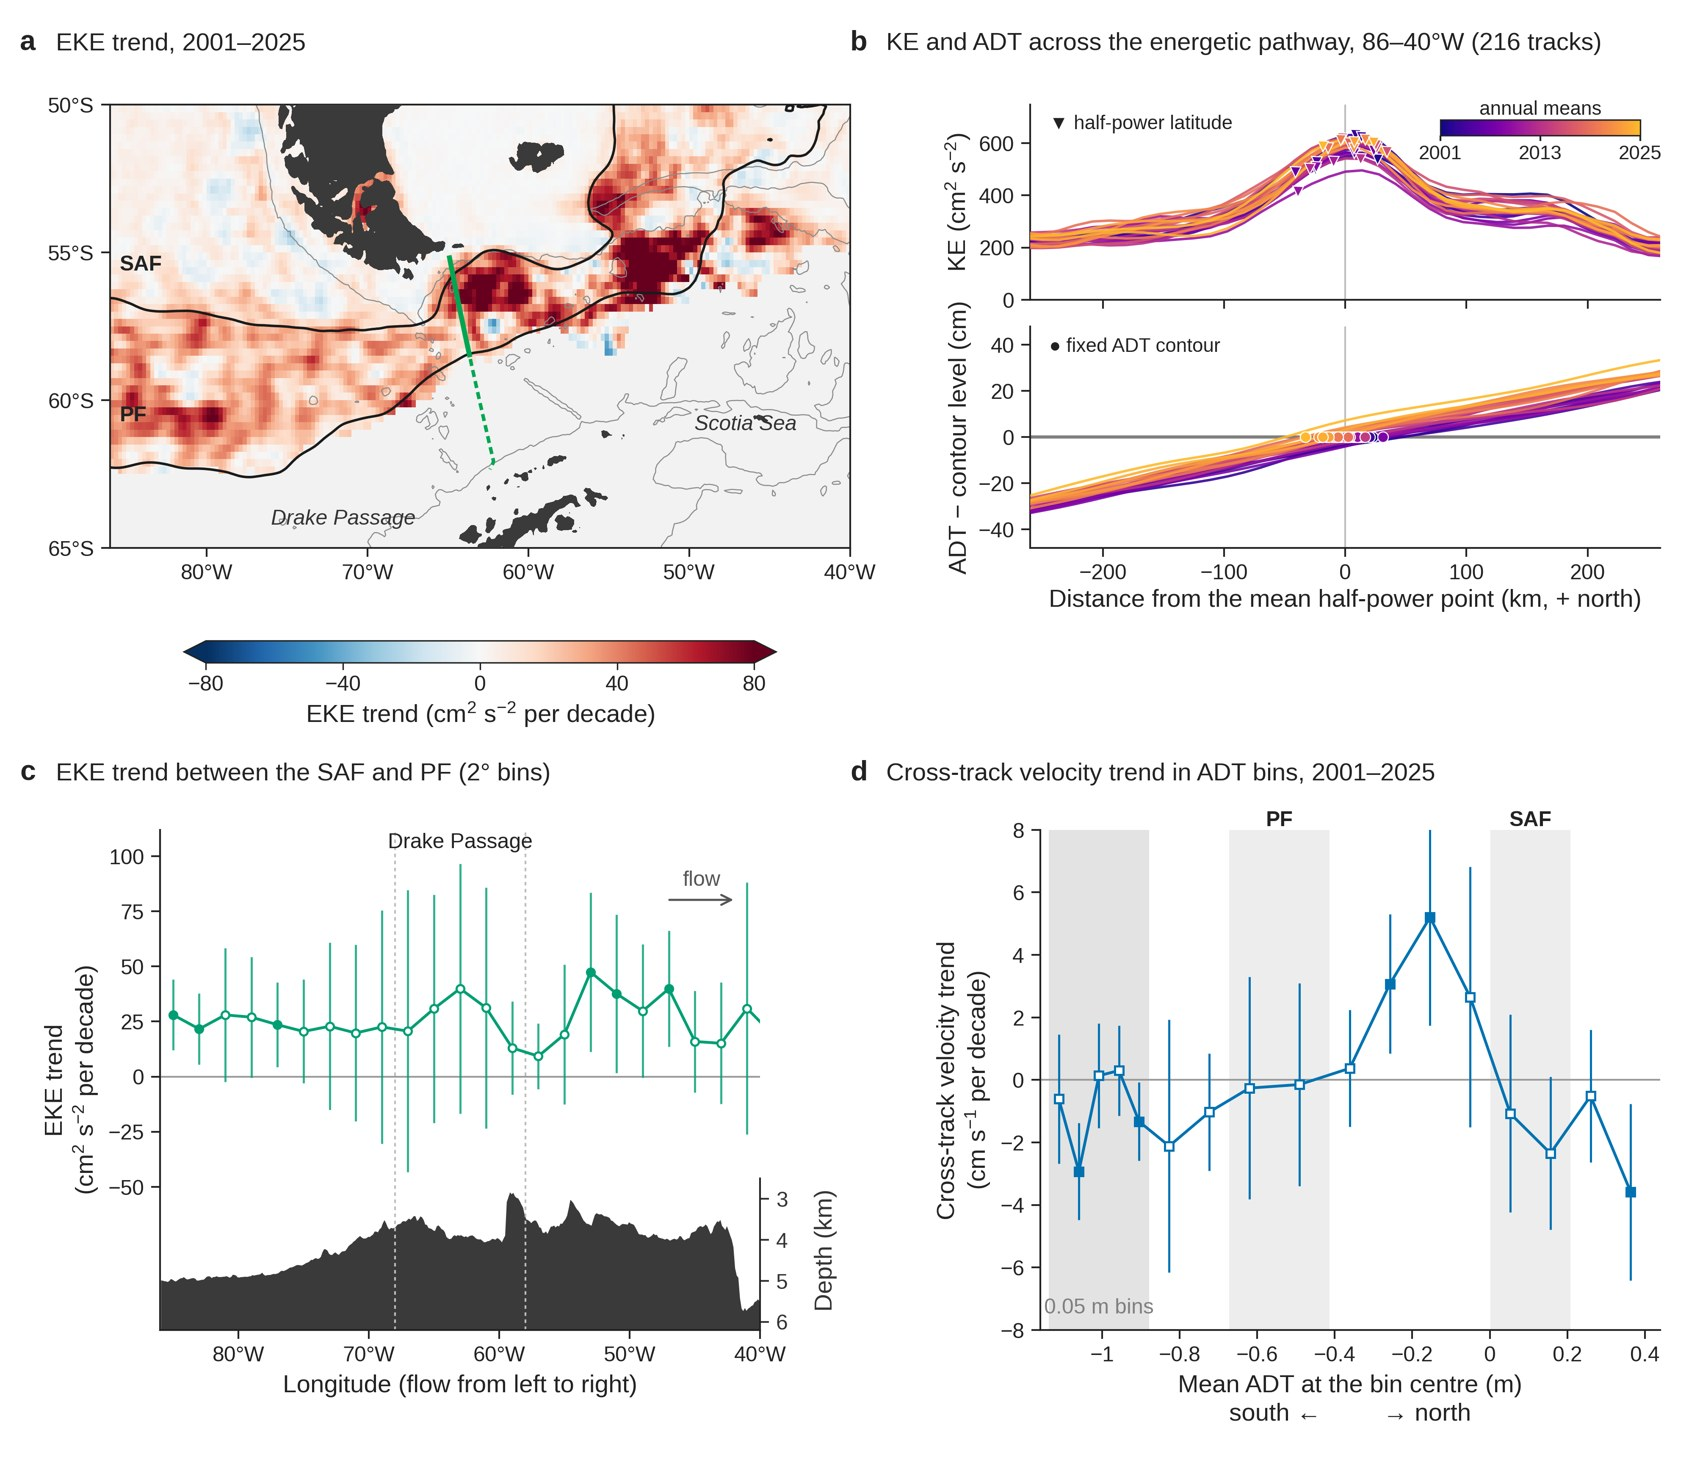

Figure2.png written to /tmp/osr11_nb_2urojmu5/png


In [5]:
render("fig2_drake.py")

## Comparison with the in situ record and drift of the ADT bins (Fig. S1)

(a) mean cross-track velocity, altimetry against the ADCP at 70–118 m; (b) trends per 25 km bin; (c) the ADT-bin trends of Fig. 2d with fixed edges and with edges that follow the rise of the section-mean ADT (`scripts/03_drake/03w_adt_bin_drift.py`).

In [6]:
print((OUT / "c04" / "c04_log.txt").read_text().splitlines()[0])
C = pd.read_csv(OUT / "c04" / "c04_results.csv")
short = {v: ("fixed edges" if v.startswith("fixed") else "edges follow the ADT rise" if "secular" in v else "edges follow the ADT anomaly") for v in C.variant.unique()}
C.assign(variant=C.variant.map(short)).pivot_table(index="bin_psic", columns="variant", values="slope_dec").sort_index(ascending=False).round(2)

section-mean ADT (always ice-free points, 58 of 121): Theil-Sen rise 1.84 cm per decade; total over the record 4.6 cm; bin widths 5-15 cm


variant,edges follow the ADT anomaly,edges follow the ADT rise,fixed edges
bin_psic,,,
-0.25,-1.75,-2.1,-3.59
-0.35,-0.85,-1.1,-0.13
-0.45,-2.6,-2.22,-2.57
-0.55,1.07,0.51,-1.02
-0.65,3.96,3.63,2.94
-0.75,4.35,5.04,5.38
-0.85,2.56,3.02,2.9
-0.95,0.18,0.23,0.23
-1.07,-0.18,-0.02,-0.15


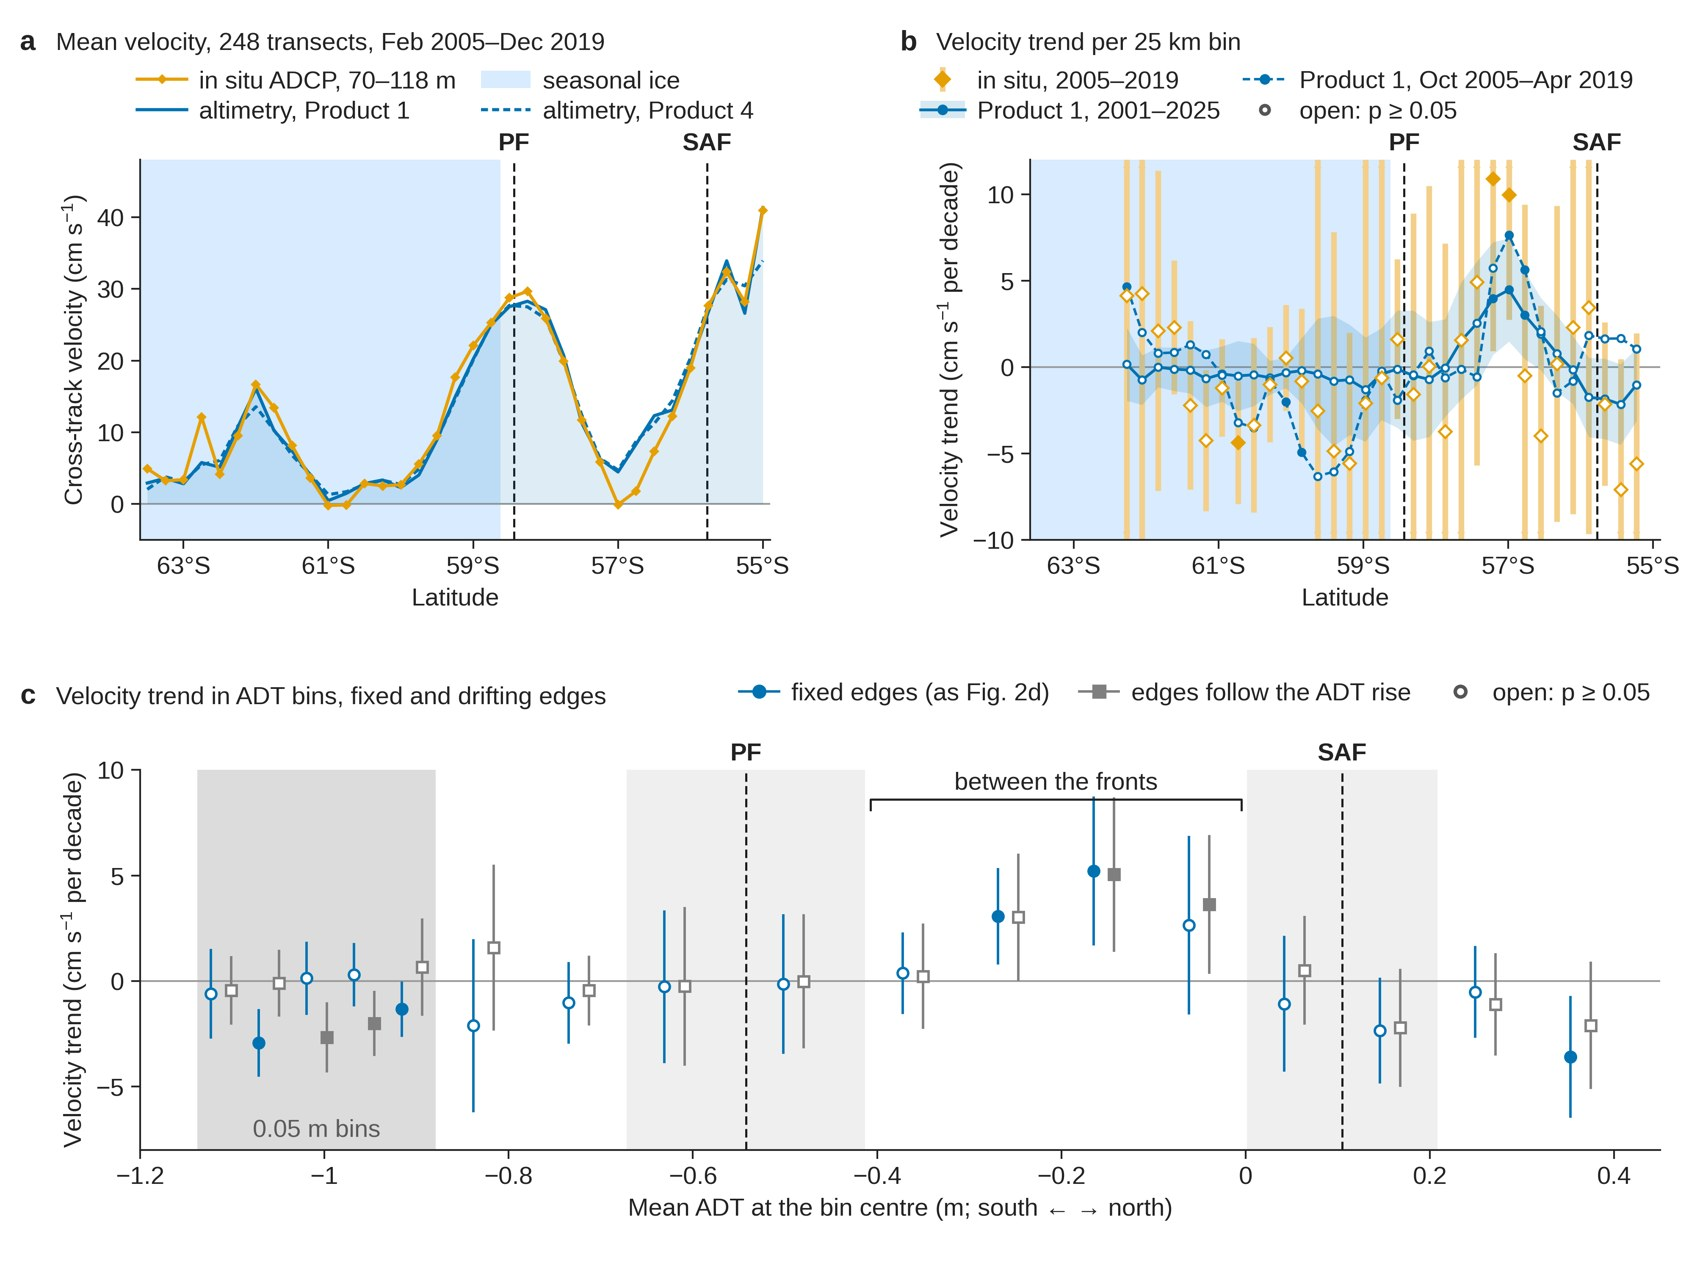

FigureS1.png written to /tmp/osr11_nb_2urojmu5/png


In [7]:
render("figS1_drake_section.py")

## Timing of the EKE increase (Fig. S2)

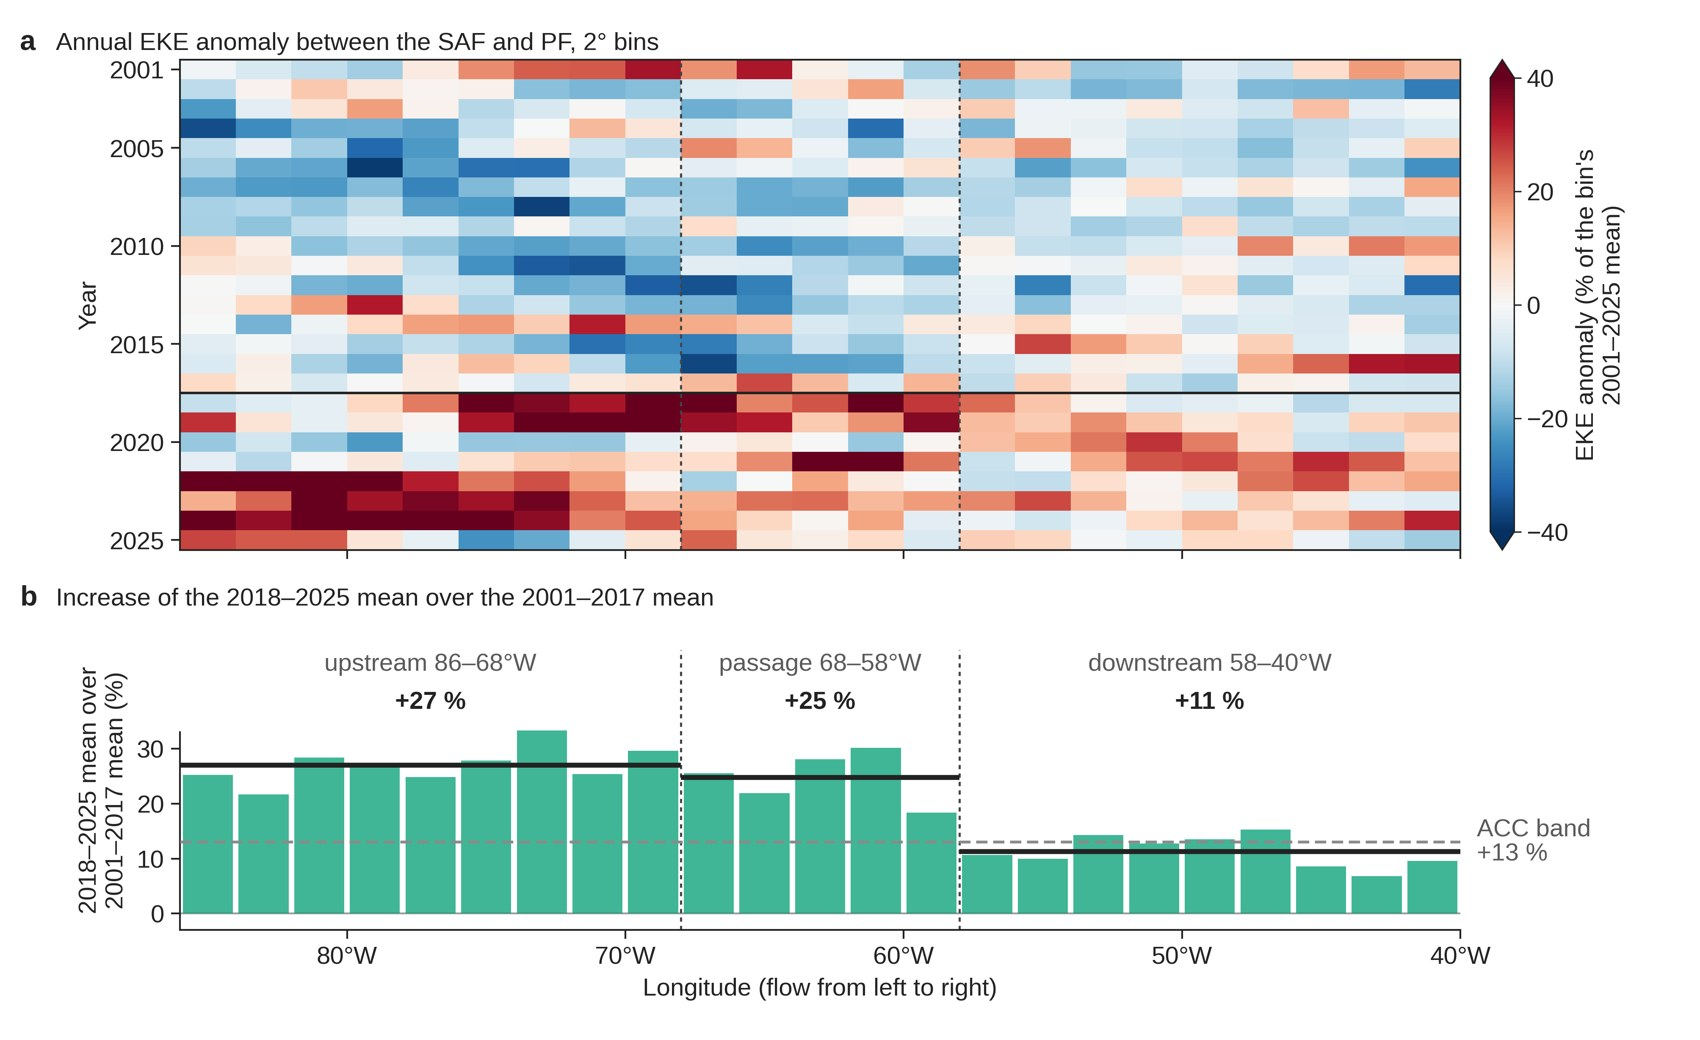

FigureS2.png written to /tmp/osr11_nb_2urojmu5/png


In [8]:
render("figS2_timing.py")